# №7 практикалық дәріс және зертханалық жұмыс **Тақырып:** Бағандық диаграмма және нүктелік график  **Студент:** Quantqan Shapagat **Топ:** 24-ПО-103-3к-5

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
print('pandas нұсқасы:', pd.__version__)
print('Визуализация жұмысына дайын!')


pandas нұсқасы: 2.2.3
Визуализация жұмысына дайын!


In [ ]:
csv_data = """session_id,protocol,service,duration_sec,bytes_sent,failed_logins,connections_1min,label
S001,tcp,http,12,850,0,8,normal
S002,tcp,https,18,1320,0,12,normal
S003,udp,dns,3,240,0,18,normal
S004,tcp,ssh,25,980,1,10,normal
S005,icmp,ping,1,90,0,5,normal
S006,tcp,http,35,2100,0,16,normal
S007,udp,dns,5,310,0,22,normal
S008,tcp,https,42,2800,0,20,normal
S009,tcp,ssh,8,760,2,15,normal
S010,icmp,ping,2,110,0,6,normal
S011,udp,stream,55,4200,0,25,normal
S012,tcp,http,28,1750,0,14,normal
S013,tcp,ssh,4,5200,7,95,suspicious
S014,udp,dns,2,4800,0,120,suspicious
S015,tcp,http,6,6900,4,135,suspicious
S016,icmp,ping,1,2500,0,150,suspicious
S017,tcp,ssh,9,8100,8,170,suspicious
S018,udp,dns,3,5700,0,145,suspicious
S019,tcp,https,14,9200,5,110,suspicious
S020,tcp,http,7,7600,3,160,suspicious
S021,icmp,ping,2,3300,0,130,suspicious
S022,udp,stream,11,8800,1,105,suspicious
S023,tcp,ssh,5,6100,9,180,suspicious
S024,tcp,https,16,10200,6,125,suspicious
"""
with open('network_traffic_07.csv', 'w', encoding='utf-8') as file:
 file.write(csv_data)
print('network_traffic_07.csv файлы жасалды')

network_traffic_07.csv файлы жасалды


In [ ]:
df = pd.read_csv("network_traffic_07.csv")

print('Кесте өлшемі:', df.shape)
display(df.head())

Кесте өлшемі: (24, 8)


,session_id,protocol,service,duration_sec,bytes_sent,failed_logins,connections_1min,label
0,S001,tcp,http,12,850,0,8,normal
1,S002,tcp,https,18,1320,0,12,normal
2,S003,udp,dns,3,240,0,18,normal
3,S004,tcp,ssh,25,980,1,10,normal
4,S005,icmp,ping,1,90,0,5,normal


In [ ]:
print('Бағандар:')
print(df.columns.tolist())

print('\nБос мәндер:')
print(df.isna().sum())

print('\nДерек түрлері:')
print(df.dtypes)

print('\nСыныптар саны:')
print(df['label'].value_counts())

Бағандар:
['session_id', 'protocol', 'service', 'duration_sec', 'bytes_sent', 'failed_logins', 'connections_1min', 'label']

Бос мәндер:
session_id          0
protocol            0
service             0
duration_sec        0
bytes_sent          0
failed_logins       0
connections_1min    0
label               0
dtype: int64

Дерек түрлері:
session_id          object
protocol            object
service             object
duration_sec         int64
bytes_sent           int64
failed_logins        int64
connections_1min     int64
label               object
dtype: object

Сыныптар саны:
label
normal        12
suspicious    12
Name: count, dtype: int64


In [ ]:
protocol_counts = df['protocol'].value_counts()

print(protocol_counts)
print('\nЕң жиі протокол:', protocol_counts.idxmax())
print('Оның саны:', protocol_counts.max())


protocol
tcp     14
udp      6
icmp     4
Name: count, dtype: int64

Ең жиі протокол: tcp
Оның саны: 14


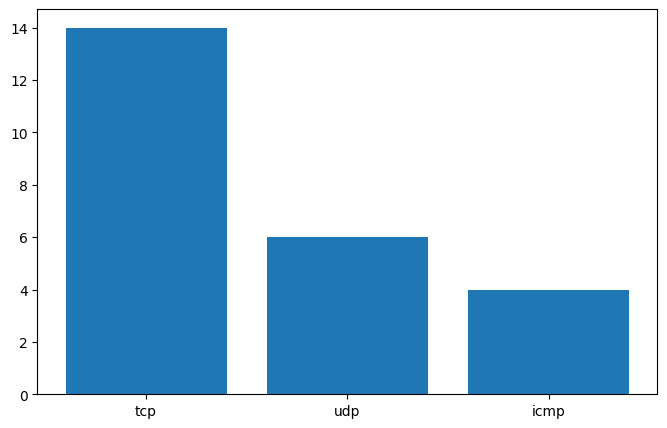

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(protocol_counts.index, protocol_counts.values)
plt.show()

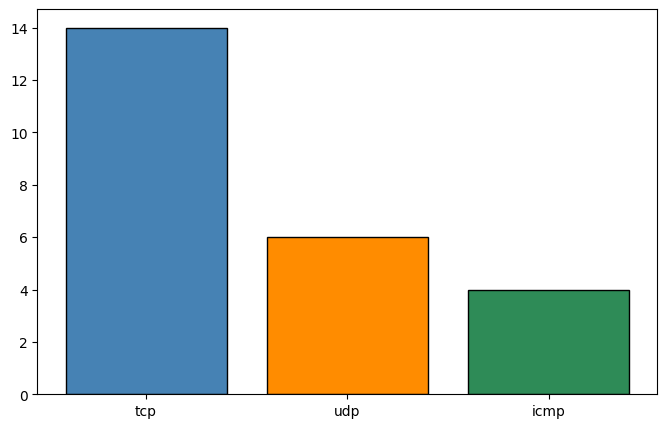

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
 protocol_counts.index,
 protocol_counts.values,
 color=['steelblue', 'darkorange', 'seagreen'],
 edgecolor='black'
)

/tmp/ipykernel_3087/2744495736.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


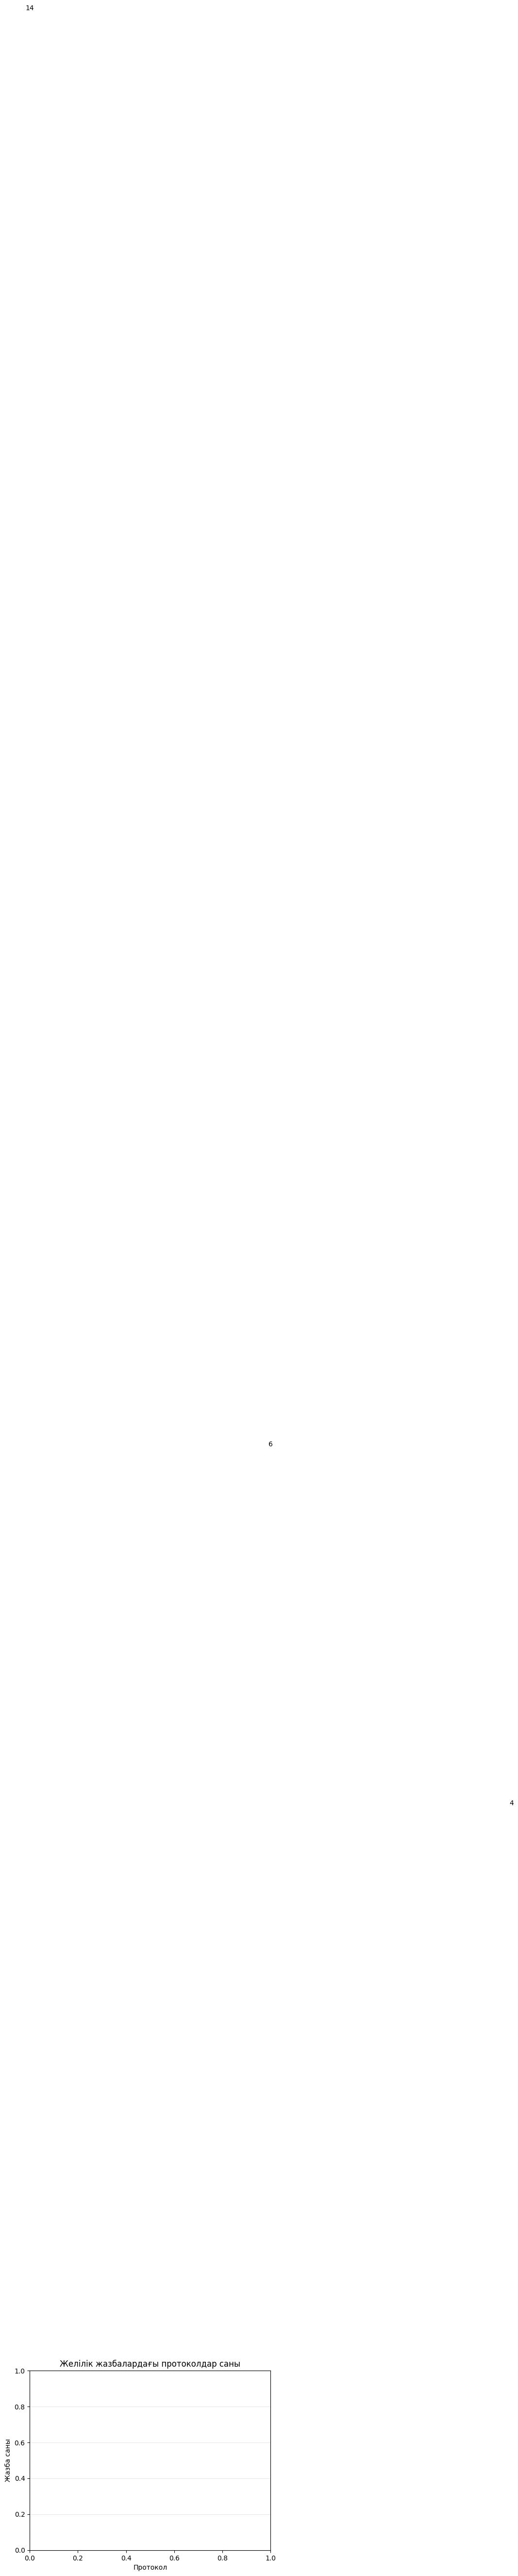

In [ ]:
plt.title('Желілік жазбалардағы протоколдар саны')
plt.xlabel('Протокол')
plt.ylabel('Жазба саны')
plt.grid(axis='y', alpha=0.3)

for bar in bars:
 height = bar.get_height()
 plt.text(
 bar.get_x() + bar.get_width() / 2,
 height + 0.15,
 str(int(height)),
 ha='center'
 )

plt.tight_layout()
plt.savefig('01_protocol_bar.png', dpi=150, bbox_inches='tight')
plt.show()

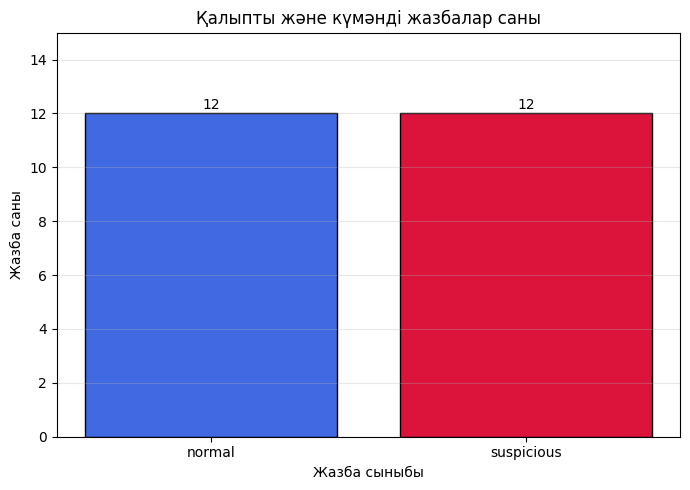

In [ ]:
label_counts = df['label'].value_counts()

plt.figure(figsize=(7, 5))

bars = plt.bar(
 label_counts.index,
 label_counts.values,
 color=['royalblue', 'crimson'],
 edgecolor='black'

)

plt.title('Қалыпты және күмәнді жазбалар саны')
plt.xlabel('Жазба сыныбы')
plt.ylabel('Жазба саны')
plt.ylim(0, label_counts.max() + 3)
plt.grid(axis='y', alpha=0.3)

for bar in bars:
 plt.text(
 bar.get_x() + bar.get_width() / 2,
 bar.get_height() + 0.15,
 str(int(bar.get_height())),
 ha='center'
 )

plt.tight_layout()
plt.savefig('02_label_bar.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
protocol_label = pd.crosstab(df['protocol'], df['label'])
display(protocol_label)

label,normal,suspicious
protocol,,
icmp,2,2
tcp,7,7
udp,3,3


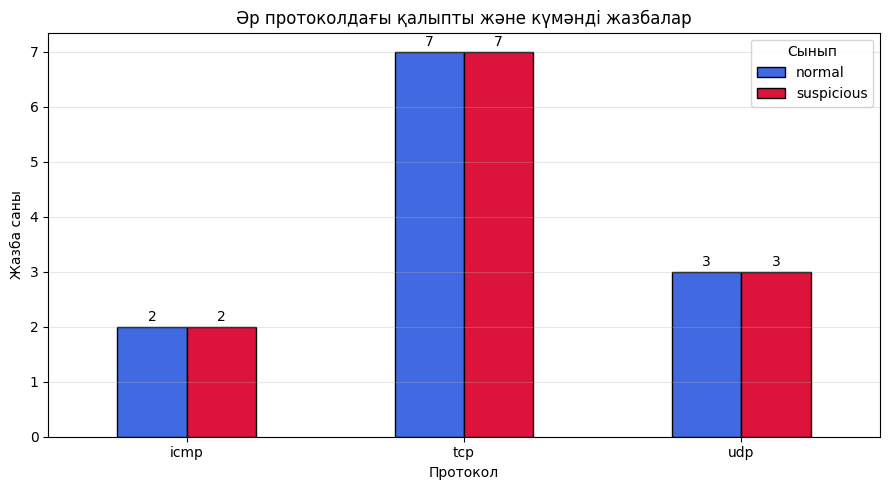

In [ ]:
ax = protocol_label.plot(
 kind='bar',
 figsize=(9, 5),
 color=['royalblue', 'crimson'],
 edgecolor='black'
)

plt.title('Әр протоколдағы қалыпты және күмәнді жазбалар')
plt.xlabel('Протокол')
plt.ylabel('Жазба саны')
plt.xticks(rotation=0)
plt.legend(title='Сынып')
plt.grid(axis='y', alpha=0.3)

for container in ax.containers:
  ax.bar_label(container, padding=2)

plt.tight_layout()
plt.savefig('03_protocol_label_bar.png', dpi=150, bbox_inches='tight')
plt.show()

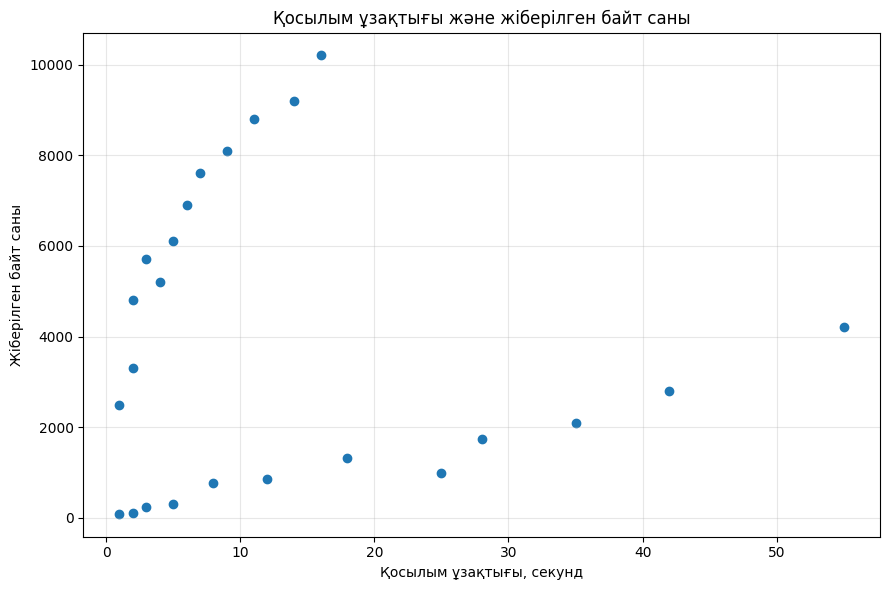

In [ ]:
plt.figure(figsize=(9, 6))
plt.scatter(df['duration_sec'], df['bytes_sent'])

plt.title('Қосылым ұзақтығы және жіберілген байт саны')
plt.xlabel('Қосылым ұзақтығы, секунд')
plt.ylabel('Жіберілген байт саны')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('04_duration_bytes_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
normal = df[df['label'] == 'normal']
suspicious = df[df['label'] == 'suspicious']

print('Қалыпты жазба саны:', len(normal))
print('Күмәнді жазба саны:', len(suspicious))

Қалыпты жазба саны: 12
Күмәнді жазба саны: 12


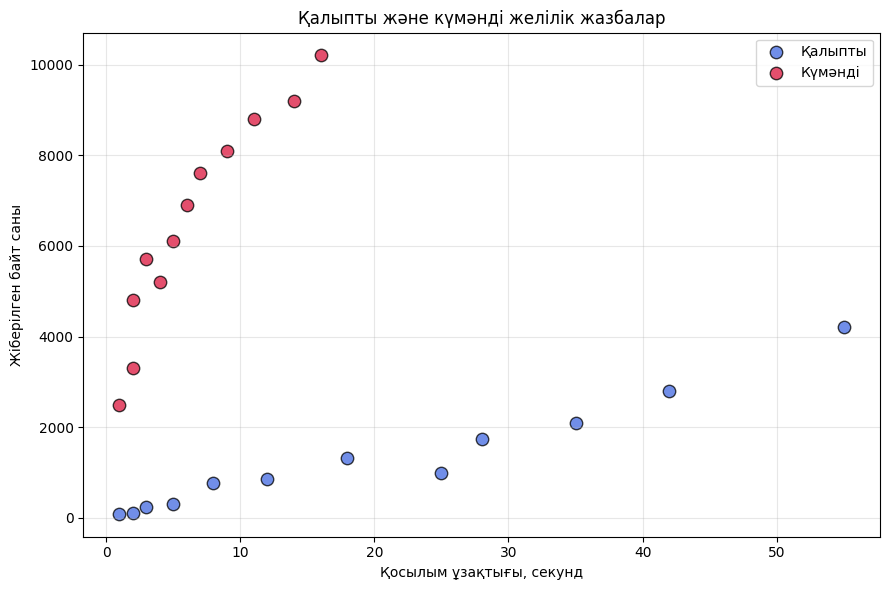

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
 normal['duration_sec'],
 normal['bytes_sent'],
 color='royalblue',
 label='Қалыпты',
 s=80,
 alpha=0.75,
 edgecolor='black'
)

plt.scatter(
 suspicious['duration_sec'],
 suspicious['bytes_sent'],
 color='crimson',
 label='Күмәнді',
 s=80,
 alpha=0.75,
 edgecolor='black'
)

plt.title('Қалыпты және күмәнді желілік жазбалар')
plt.xlabel('Қосылым ұзақтығы, секунд')
plt.ylabel('Жіберілген байт саны')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('05_colored_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

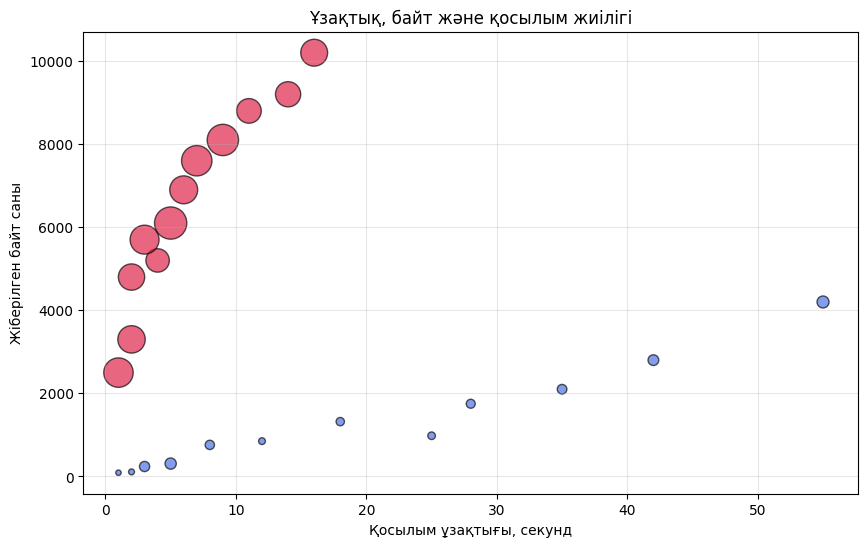

In [ ]:
colors = df['label'].map({
 'normal': 'royalblue',
 'suspicious': 'crimson'
})

point_sizes = df['connections_1min'] * 3

plt.figure(figsize=(10, 6))
plt.scatter(
 df['duration_sec'],
 df['bytes_sent'],
 c=colors,
 s=point_sizes,
 alpha=0.65,
 edgecolor='black'
)

plt.title('Ұзақтық, байт және қосылым жиілігі')
plt.xlabel('Қосылым ұзақтығы, секунд')
plt.ylabel('Жіберілген байт саны')
plt.grid(alpha=0.3)
plt.show()


In [ ]:
high_bytes = df[df['bytes_sent'] >= 8000]

display(
 high_bytes[
 ['session_id', 'protocol', 'duration_sec',
 'bytes_sent', 'connections_1min', 'label']
 ].sort_values('bytes_sent', ascending=False)
)

,session_id,protocol,duration_sec,bytes_sent,connections_1min,label
23,S024,tcp,16,10200,125,suspicious
18,S019,tcp,14,9200,110,suspicious
21,S022,udp,11,8800,105,suspicious
16,S017,tcp,9,8100,170,suspicious


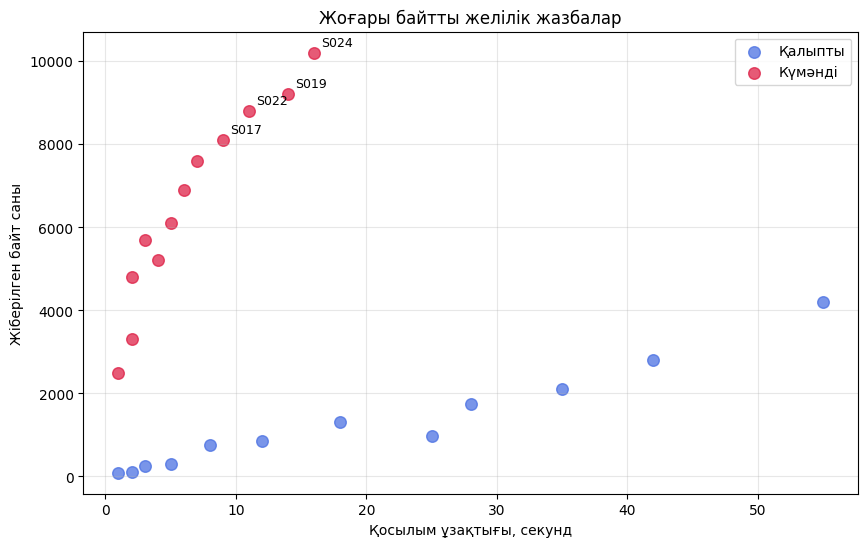

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
 normal['duration_sec'], normal['bytes_sent'],
 color='royalblue', label='Қалыпты', s=70, alpha=0.7
)
plt.scatter(
 suspicious['duration_sec'], suspicious['bytes_sent'],
 color='crimson', label='Күмәнді', s=70, alpha=0.7
)

for _, row in high_bytes.iterrows():
 plt.annotate(
 row['session_id'],
 (row['duration_sec'], row['bytes_sent']),
 xytext=(5, 5),
 textcoords='offset points',
 fontsize=9
 )

plt.title('Жоғары байтты желілік жазбалар')
plt.xlabel('Қосылым ұзақтығы, секунд')
plt.ylabel('Жіберілген байт саны')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

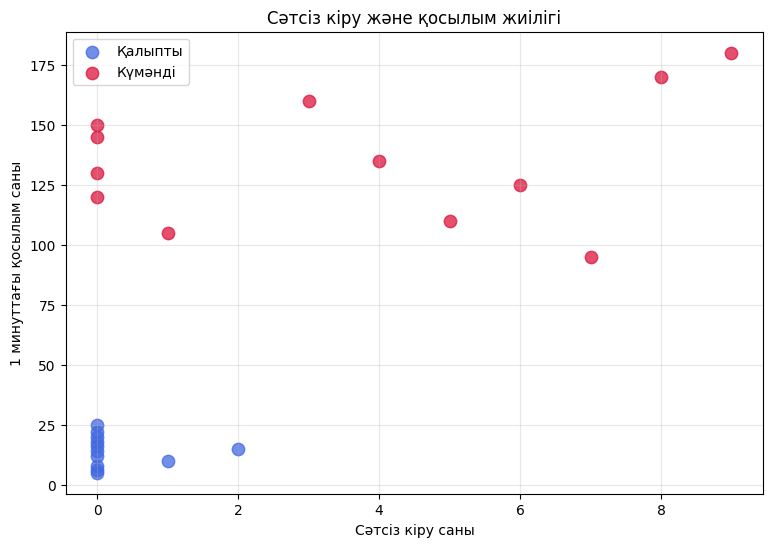

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
 normal['failed_logins'],
 normal['connections_1min'],
 color='royalblue',
 label='Қалыпты',
 s=80,
 alpha=0.75
)

plt.scatter(
 suspicious['failed_logins'],
 suspicious['connections_1min'],
 color='crimson',
 label='Күмәнді',
 s=80,
 alpha=0.75
)

plt.title('Сәтсіз кіру және қосылым жиілігі')
plt.xlabel('Сәтсіз кіру саны')
plt.ylabel('1 минуттағы қосылым саны')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

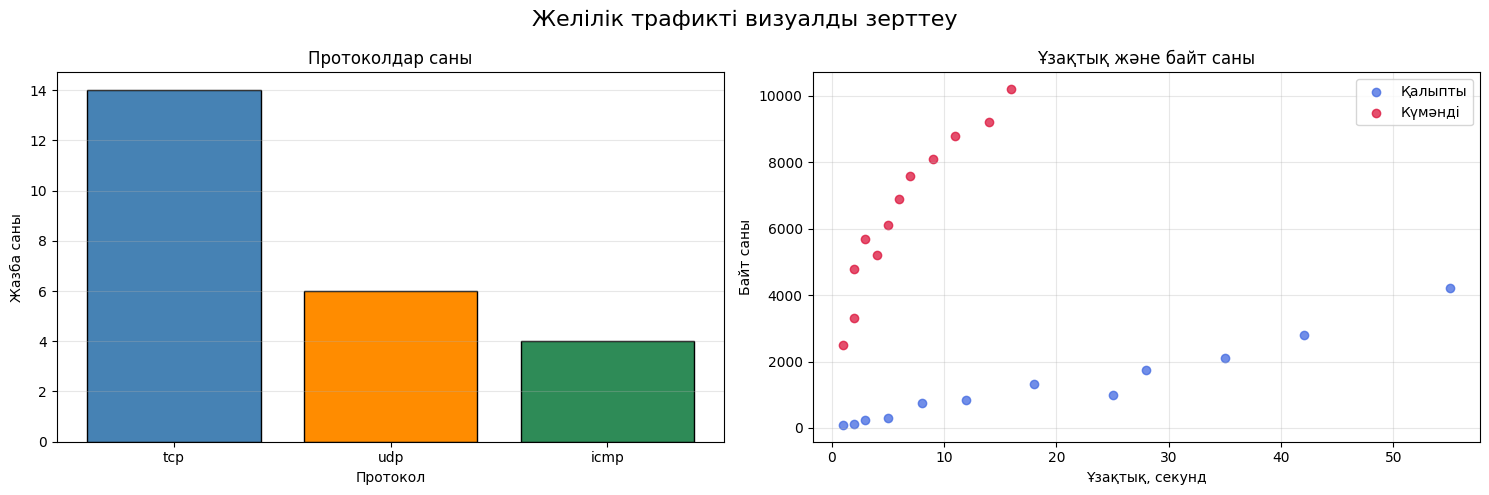

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
 protocol_counts.index,
 protocol_counts.values,
 color=['steelblue', 'darkorange', 'seagreen'],
 edgecolor='black'
)

axes[0].set_title('Протоколдар саны')
axes[0].set_xlabel('Протокол')
axes[0].set_ylabel('Жазба саны')
axes[0].grid(axis='y', alpha=0.3)

axes[1].scatter(
 normal['duration_sec'], normal['bytes_sent'],
 color='royalblue', label='Қалыпты', alpha=0.75
)
axes[1].scatter(
 suspicious['duration_sec'], suspicious['bytes_sent'],
 color='crimson', label='Күмәнді', alpha=0.75
)

axes[1].set_title('Ұзақтық және байт саны')
axes[1].set_xlabel('Ұзақтық, секунд')
axes[1].set_ylabel('Байт саны')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Желілік трафикті визуалды зерттеу', fontsize=16)
plt.tight_layout()
plt.savefig('student_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
import zipfile

result_files = [
 'network_traffic_07.csv',
 '01_protocol_bar.png',
 '02_label_bar.png',
 '03_protocol_label_bar.png',
 '04_duration_bytes_scatter.png',
 '05_colored_scatter.png',
 'student_dashboard.png'
]

archive_name = 'ML_07_results.zip'

with zipfile.ZipFile(archive_name, 'w') as archive:
 for file_name in result_files:
  archive.write(file_name)

print('Архив дайын:', archive_name)
files.download(archive_name)


Архив дайын: ML_07_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

1-қорытынды:
Ең жиі кездесетін протокол — TCP, оның саны 14 жазба. UDP протоколы 6 рет, ал ең аз кездесетін ICMP протоколы 4 рет кездеседі. Сондықтан желілік трафикте TCP протоколы басым екенін байқауға болады.

2-қорытынды:
Қалыпты және күмәнді жазбалардың жалпы саны бірдей — 12 қалыпты және 12 күмәнді жазба. TCP протоколында 7 қалыпты және 7 күмәнді, UDP протоколында 3 қалыпты және 3 күмәнді, ICMP протоколында 2 қалыпты және 2 күмәнді жазба бар. Демек, әр протоколда қалыпты және күмәнді жазбалардың саны тең.

3-қорытынды:
Нүктелік графикте күмәнді жазбалардың көпшілігі 4800–10200 байт аралығында орналасқан және олардың көбі қысқа уақыт ішінде көп көлемде дерек жіберген. Қалыпты жазбалардың жіберілген байт саны негізінен төмен, ал қосылым ұзақтығы кеңірек аралықта орналасқан. Сондықтан duration_sec пен bytes_sent белгілері бойынша қалыпты және күмәнді жазбалардың арасында айырмашылық байқалады.

4-қорытынды:
failed_logins және connections_1min графигінде екі сынып анық бөлінеді. Қалыпты жазбаларда 1 минуттағы қосылым саны шамамен 5–25, ал күмәнді жазбаларда 95–180 аралығында. Осыған байланысты қосылым жиілігі күмәнді желілік әрекеттерді анықтауға көмектесетін маңызды белгі болып табылады.